# Gravidade de acidentes nas rodovias federais — Equipe 9

Este notebook é a análise de Data Science do projeto.
O código de limpeza fica em `src/`. A app em Streamlit usa o mesmo código.

**Roteiro do Checkpoint 1**

1. Entendimento do negócio (CRISP-DM)
2. Entendimento dos dados
3. Preparação dos dados (Data Wrangling)
4. Regressão linear múltipla
5. Clustering K-Means

## 1. Entendimento do negócio

**Problema.** As rodovias federais têm cerca de 70 mil acidentes por ano. Cerca de 7% desses acidentes têm pelo menos uma morte.

**Pergunta central.** O que faz um acidente numa rodovia federal ser fatal?

**Hipótese de intervenção.** A duplicação de trechos de pista simples reduz a chance de um acidente ser fatal.

**Decisão que o projeto apoia.** Se a hipótese for verdadeira, o projeto indica os trechos onde a duplicação tem o maior ganho.

**Critério de sucesso.** O modelo identifica os acidentes fatais com recall e precisão melhores que um modelo de base.
A acurácia não serve como critério: um modelo que sempre diz "não fatal" acerta cerca de 93% dos casos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from carregar import carregar
from colunas import ADMINISTRATIVAS, ALVO, VAZAMENTO
from limpeza import (
    LIMITES_BRASIL,
    VARIANTES_CAUSA,
    agrupar_categorias,
    marcar_faltantes,
    padronizar_textos,
    remover_coordenadas_invalidas,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

ANOS = range(2017, 2026)

## 2. Entendimento dos dados

**Fonte.** [Dados abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf), agrupados por ocorrência. Cada linha é um acidente.

**Período.** De 2017 a 2025. O arquivo de 2026 fica fora, porque o ano ainda não terminou.

**Leitura.** A função `carregar()` faz cinco operações em cada arquivo:

1. Lê o CSV (`latin1`, separador `;`).
2. Confere se as colunas obrigatórias existem.
3. Remove as colunas administrativas (`id`, `regional`, `delegacia`, `uop`).
4. Converte a vírgula decimal de `latitude`, `longitude` e `km` e converte as datas.
5. Remove as linhas sem classificação (10 linhas de 2017 a 2025) e cria o alvo `fatal`.

O campo `tracado_via` pode ter mais de um valor separado por `;`, por exemplo `"Reta;Declive"`.
O CSV coloca esses valores entre aspas, então a leitura não divide o campo. Todas as linhas têm 30 campos.

In [2]:
partes = []

for ano in ANOS:
    partes.append(carregar(f"../data/raw/datatran{ano}.csv"))

df_bruto = pd.concat(partes, ignore_index=True)
df_bruto["ano"] = df_bruto["data_inversa"].dt.year

print(f"Acidentes carregados: {len(df_bruto):,}".replace(",", "."))

Acidentes carregados: 632.703


### 2.1 Inspeção da estrutura

In [3]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 632703 entries, 0 to 632702
Data columns (total 28 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   data_inversa            632703 non-null  datetime64[us]
 1   dia_semana              632703 non-null  str           
 2   horario                 632703 non-null  str           
 3   uf                      632703 non-null  str           
 4   br                      632703 non-null  Int64         
 5   km                      632703 non-null  float64       
 6   municipio               632703 non-null  str           
 7   causa_acidente          632703 non-null  str           
 8   tipo_acidente           632663 non-null  str           
 9   classificacao_acidente  632703 non-null  str           
 10  fase_dia                632703 non-null  str           
 11  sentido_via             632703 non-null  str           
 12  condicao_metereologica  632703 non-null  

As colunas de vítimas (`mortos`, `feridos`, `ilesos` e outras) ficam como texto. O modelo não usa essas colunas,
porque elas descrevem o resultado do acidente (vazamento do alvo):

In [4]:
print("Vazamento:", ", ".join(VAZAMENTO))
print("Administrativas (já removidas):", ", ".join(ADMINISTRATIVAS))

Vazamento: classificacao_acidente, mortos, feridos_leves, feridos_graves, feridos, ilesos, ignorados
Administrativas (já removidas): id, regional, delegacia, uop


In [5]:
df_bruto[["km", "pessoas", "veiculos", "latitude", "longitude"]].describe().round(2)

,km,pessoas,veiculos,latitude,longitude
count,632703.00,632703.0,632703.0,6.327030e+05,6.327030e+05
mean,260.30,2.53,1.96,-1.720370e+03,-6.545700e+03
std,227.49,2.05,1.09,1.299726e+06,5.050540e+06
min,0.00,1.0,1.0,-1.033383e+09,-4.016764e+09
25%,76.90,2.0,1.0,-2.525000e+01,-5.025000e+01
50%,194.40,2.0,2.0,-2.041000e+01,-4.767000e+01
75%,409.00,3.0,2.0,-1.275000e+01,-4.252000e+01
max,1470.00,95.0,131.0,1.630000e+02,7.170000e+02


O `describe()` mostra dois problemas:

- `latitude` e `longitude` têm valores impossíveis (por exemplo, uma longitude de −4 bilhões).
- `pessoas` e `veiculos` têm valores extremos (até 95 pessoas e 131 veículos).

A seção 3.5 trata os dois problemas.

In [6]:
df_bruto.select_dtypes(include="str").describe().T

,count,unique,top,freq
dia_semana,632703,7,sábado,104336
horario,632703,1440,19:00:00,9190
uf,632703,27,MG,83427
municipio,632703,2156,BRASILIA,9039
causa_acidente,632703,91,Falta de Atenção à Condução,107786
tipo_acidente,632663,21,Colisão traseira,119331
classificacao_acidente,632703,3,Com Vítimas Feridas,462965
fase_dia,632703,4,Pleno dia,347240
sentido_via,632703,3,Crescente,337627
condicao_metereologica,632703,10,Céu Claro,377737


### 2.2 O alvo: acidentes fatais por ano

In [7]:
por_ano = df_bruto.groupby("ano").agg(acidentes=(ALVO, "size"), fatais=(ALVO, "sum"))
por_ano["% fatais"] = (por_ano["fatais"] / por_ano["acidentes"] * 100).round(2)
por_ano

,acidentes,fatais,% fatais
ano,,,
2017,89566,5184,5.79
2018,69332,4508,6.50
2019,67557,4599,6.81
2020,63583,4525,7.12
2021,64566,4665,7.23
2022,64605,4664,7.22
2023,67765,4858,7.17
2024,73201,5225,7.14
2025,72528,5209,7.18


A classe fatal é a minoria (cerca de 7%). Os modelos precisam de pesos de classe ou de um limiar de decisão ajustado.

Em 2017, a taxa de fatais é mais baixa (5,8%) que nos outros anos. Os dados não mostram a causa dessa diferença.

### 2.3 Evidência inicial da hipótese

In [8]:
frontal = df_bruto[df_bruto["tipo_acidente"] == "Colisão frontal"]

evidencia = pd.DataFrame({
    "acidentes": df_bruto.groupby("tipo_pista").size(),
    "% fatais": df_bruto.groupby("tipo_pista")[ALVO].mean() * 100,
    "% fatais em colisão frontal": frontal.groupby("tipo_pista")[ALVO].mean() * 100,
}).round(1)

evidencia.loc[["Simples", "Dupla", "Múltipla"]]

,acidentes,% fatais,% fatais em colisão frontal
tipo_pista,,,
Simples,315718,9.3,30.0
Dupla,263068,4.6,16.6
Múltipla,53917,3.9,11.3


Na pista simples, a taxa de fatais é cerca de duas vezes a taxa da pista dupla.
Esta comparação não controla outros fatores (clima, causa, traçado). As próximas etapas fazem esse controle.

## 3. Preparação dos dados (Data Wrangling)

Cada passo tem três partes: o problema, a evidência nos dados e a ação.
As funções ficam em `src/limpeza.py`.

### 3.1 Duplicatas

**Problema.** Alguns acidentes estão registrados duas vezes, com `id` diferente e todas as outras colunas iguais.

**Ação.** Remova as linhas repetidas. O `carregar()` já removeu o `id`, então duas linhas iguais são o mesmo acidente.

In [9]:
duplicadas = df_bruto[df_bruto.duplicated(keep=False)]
print(f"Linhas repetidas: {df_bruto.duplicated().sum()}")

duplicadas[["data_inversa", "horario", "uf", "br", "km", "tipo_acidente", "classificacao_acidente"]].sort_values(["data_inversa", "horario"]).head(6)

Linhas repetidas: 10


,data_inversa,horario,uf,br,km,tipo_acidente,classificacao_acidente
19235,2017-10-20,14:25:00,SC,282,483.9,Colisão traseira,Sem Vítimas
75524,2017-10-20,14:25:00,SC,282,483.9,Colisão traseira,Sem Vítimas
79146,2017-11-11,17:00:00,GO,60,201.8,Colisão com objeto estático,Sem Vítimas
79147,2017-11-11,17:00:00,GO,60,201.8,Colisão com objeto estático,Sem Vítimas
80532,2017-11-19,15:40:00,RJ,40,113.0,Colisão traseira,Com Vítimas Feridas
80533,2017-11-19,15:40:00,RJ,40,113.0,Colisão traseira,Com Vítimas Feridas


In [10]:
df = df_bruto.drop_duplicates(ignore_index=True)
print(f"Antes: {len(df_bruto)} linhas. Depois: {len(df)} linhas.")

Antes: 632703 linhas. Depois: 632693 linhas.


### 3.2 Valores faltantes escritos como texto

**Problema.** A PRF escreve alguns valores faltantes como texto. Para o pandas, esses textos são categorias válidas.

| Coluna | Texto | Significado |
|---|---|---|
| `condicao_metereologica` | `"Ignorado"` | O clima não foi registrado |
| `sentido_via` | `"Não Informado"` | O sentido não foi registrado |
| `br` | `0` | A rodovia não foi registrada |

Quando `br` é 0, `km` também é 0 e `sentido_via` é `"Não Informado"`. A PRF não registrou o ponto do acidente na rodovia.

**Ação.** Mude esses valores para `NaN`. Mude também o `km` das linhas com `br` = 0.

In [11]:
sem_rodovia = df["br"] == 0

print("Clima 'Ignorado':", (df["condicao_metereologica"] == "Ignorado").sum())
print("Sentido 'Não Informado':", (df["sentido_via"] == "Não Informado").sum())
print("br = 0:", sem_rodovia.sum())
print("br = 0 com km = 0 e sentido 'Não Informado':", (sem_rodovia & (df["km"] == 0) & (df["sentido_via"] == "Não Informado")).sum())

Clima 'Ignorado': 8947
Sentido 'Não Informado': 1407
br = 0: 1407
br = 0 com km = 0 e sentido 'Não Informado': 1407


In [12]:
df = marcar_faltantes(df)

faltantes = df.isna().sum()
faltantes[faltantes > 0].to_frame("NaN")

,NaN
br,1407
km,1407
tipo_acidente,40
sentido_via,1407
condicao_metereologica,8947


### 3.3 Padronização de textos

**Problema 1.** Algumas causas mudaram de grafia entre os anos, mas o conceito não mudou.

In [13]:
variantes = df[df["causa_acidente"].isin(set(VARIANTES_CAUSA) | set(VARIANTES_CAUSA.values()))]
pd.crosstab(variantes["causa_acidente"], variantes["ano"])

ano,2018,2019,2020,2021,2022,2023,2024,2025
causa_acidente,,,,,,,,
Ingestão de álcool e/ou substâncias psicoativas pelo pedestre,247,334,305,297,264,217,0,0
Ingestão de álcool ou de substâncias psicoativas pelo pedestre,0,1,1,114,72,94,0,0
Pedestre - Ingestão de álcool/ substâncias psicoativas,0,0,0,0,0,4,169,150
Transitar no Acostamento,0,0,0,0,0,271,488,498
Transitar no acostamento,0,0,4,446,377,0,0,0


**Problema 2.** O campo `tracado_via` junta vários valores com `;`, em qualquer ordem. Por exemplo, `"Reta;Declive"` e `"Declive;Reta"` são o mesmo traçado.

**Ação.** Substitua cada variante pelo texto mais recente. Coloque as partes do traçado em ordem alfabética.

In [14]:
antes = df["tracado_via"].nunique()

df = padronizar_textos(df)

print(f"Textos diferentes em tracado_via: {antes} antes, {df['tracado_via'].nunique()} depois.")
print(f"Valores básicos do traçado: {df['tracado_via'].str.split(';').explode().nunique()}")

Textos diferentes em tracado_via: 1328 antes, 384 depois.
Valores básicos do traçado: 12


### 3.4 Mudança das categorias em 2021

**Problema.** Em 2021, a PRF trocou a lista de causas e de tipos de acidente. O dicionário de dados não documenta essa mudança.

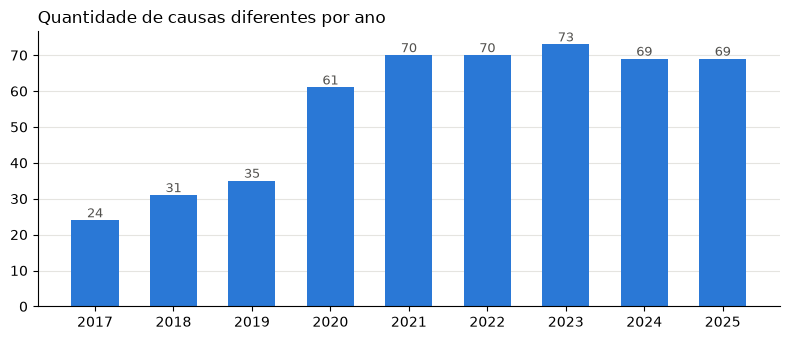

In [15]:
causas_por_ano = df.groupby("ano")["causa_acidente"].nunique()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(causas_por_ano.index, causas_por_ano.values, color="#2a78d6", width=0.6)
ax.set_title("Quantidade de causas diferentes por ano", loc="left")
ax.set_xticks(causas_por_ano.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0")
ax.set_axisbelow(True)

for ano, total in causas_por_ano.items():
    ax.annotate(str(total), (ano, total), ha="center", va="bottom", fontsize=9, color="#52514e")

plt.tight_layout()
plt.show()

In [16]:
contagem = pd.crosstab(df["causa_acidente"], df["ano"])
antigas = contagem.loc[:, :2019].sum(axis=1) > 0
novas = contagem.loc[:, 2021:].sum(axis=1) > 0

print(f"Causas que desaparecem depois de 2020: {(antigas & ~novas).sum()}")
print(f"Causas que existem nos dois períodos: {(antigas & novas).sum()}")
print(f"Causas que começam em 2020 ou 2021: {(~antigas & novas).sum()}")

contagem[antigas & ~novas].sort_values(2017, ascending=False).head(8)

Causas que desaparecem depois de 2020: 15
Causas que existem nos dois períodos: 23
Causas que começam em 2020 ou 2021: 50


ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
causa_acidente,,,,,,,,,
Falta de Atenção à Condução,34510,25840,25030,22406,0,0,0,0,0
Ingestão de Álcool,6448,5203,5420,5070,0,0,0,0,0
Não guardar distância de segurança,5836,4266,4222,3606,0,0,0,0,0
Desobediência às normas de trânsito pelo condutor,5219,7194,8106,8800,0,0,0,0,0
Defeito Mecânico no Veículo,4649,3717,3742,3742,0,0,0,0,0
Falta de Atenção do Pedestre,2390,2074,1971,1641,0,0,0,0,0
Defeito na Via,1420,1128,978,960,0,0,0,0,0
Mal Súbito,972,677,718,584,0,0,0,0,0


Em 2020, as causas novas já aparecem, mas cada uma tem menos de 40 registros. A troca completa acontece em 2021.

A maior causa de 2017 ("Falta de Atenção à Condução", 38% dos acidentes) não existe depois de 2020.
No lugar dela aparecem causas mais detalhadas, por exemplo "Reação tardia ou ineficiente do condutor".

A coluna `tipo_acidente` também muda:

In [17]:
tipos_alterados = ["Colisão com objeto estático", "Colisão com objeto em movimento", "Colisão com objeto",
                   "Colisão lateral", "Colisão lateral mesmo sentido", "Colisão lateral sentido oposto"]

pd.crosstab(df["tipo_acidente"], df["ano"]).loc[tipos_alterados]

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
tipo_acidente,,,,,,,,,
Colisão com objeto estático,7327,5061,4464,4889,0,0,0,0,0
Colisão com objeto em movimento,627,399,313,255,0,0,0,0,0
Colisão com objeto,1,0,0,27,4910,4764,4859,5121,5109
Colisão lateral,10599,8347,8347,7439,676,0,0,0,0
Colisão lateral mesmo sentido,0,1,0,12,5572,6239,7004,7906,7885
Colisão lateral sentido oposto,0,0,1,9,1609,1774,2018,2029,2152


**Ação.** O notebook mantém duas colunas para cada campo:

| Coluna | Conteúdo | Uso |
|---|---|---|
| `causa_acidente` | Texto original, com a grafia padronizada (73 causas de 2021 a 2025) | Modelos com detalhe (por exemplo, embeddings) |
| `grupo_causa` | 10 grupos que juntam as causas antigas e as novas | Comparações entre todos os anos |
| `tipo_acidente` | Texto original | Modelos com detalhe |
| `grupo_tipo` | Tipos com nomes iguais nos dois períodos | Comparações entre todos os anos |

Os grupos de causa estão em `GRUPOS_CAUSA` (`src/limpeza.py`). "Desatenção" e "infração" ficam no mesmo grupo ("Falha do condutor"),
porque, em 2021, registros passaram de uma categoria para a outra.

In [18]:
df = agrupar_categorias(df)

print(f"Causas sem grupo: {df['grupo_causa'].isna().sum()}")
print(f"Grupos de causa: {df['grupo_causa'].nunique()}")
print(f"Grupos de tipo: {df['grupo_tipo'].nunique()}")

Causas sem grupo: 0
Grupos de causa: 10
Grupos de tipo: 15


**Teste do mapeamento.** Se os grupos estão corretos, a proporção de cada grupo não muda muito de 2020 para 2021.

In [19]:
proporcao = (pd.crosstab(df["grupo_causa"], df["ano"], normalize="columns") * 100).round(1)
proporcao["variação 2020→2021"] = (proporcao[2021] - proporcao[2020]).round(1)
proporcao.sort_values(2021, ascending=False)

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025,variação 2020→2021
grupo_causa,,,,,,,,,,
Falha do condutor,53.2,55.7,57.0,56.7,55.4,59.6,63.8,65.2,66.5,-1.3
Velocidade,11.6,9.9,8.9,9.3,10.5,7.8,6.3,6.0,5.7,1.2
Veículo,7.8,7.6,7.4,8.2,7.6,7.3,7.4,7.4,7.3,-0.6
Álcool e drogas (condutor),7.3,7.7,8.2,8.2,7.3,6.9,5.4,5.4,5.2,-0.9
Via,2.9,2.8,2.5,2.6,5.1,4.8,4.4,3.7,3.8,2.5
Estado físico (condutor),5.3,4.8,4.7,4.2,4.6,4.2,4.0,4.0,4.0,0.4
Clima e natureza,6.2,4.9,4.3,4.3,4.2,3.9,3.4,3.5,3.0,-0.1
Pedestre,2.7,3.7,4.0,3.7,3.5,3.6,3.3,2.8,2.7,-0.2
Animais,2.9,2.3,2.3,2.2,1.9,2.0,2.0,2.0,1.8,-0.3


In [20]:
taxa_fatal = (df.pivot_table(index="grupo_causa", columns="ano", values=ALVO, aggfunc="mean") * 100).round(1)
taxa_fatal.sort_values(2021, ascending=False)

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
grupo_causa,,,,,,,,,
Pedestre,29.3,27.1,27.4,29.2,30.9,28.8,28.2,32.1,31.3
Velocidade,7.2,8.7,9.6,9.8,8.5,8.2,9.1,8.4,9.5
Estado físico (condutor),9.4,10.3,10.3,9.5,8.5,8.2,9.7,10.9,11.1
Falha do condutor,4.8,5.3,5.6,6.1,6.8,6.9,6.7,6.7,6.7
Via,4.4,5.4,4.4,5.4,5.7,6.4,5.9,6.3,5.8
Animais,3.6,5.7,5.4,4.9,4.7,6.1,6.8,5.5,5.5
Clima e natureza,4.1,5.1,5.5,4.7,4.7,4.2,3.8,4.5,3.6
Álcool e drogas (condutor),6.4,5.1,5.5,5.8,4.2,4.1,4.4,4.6,4.9
Veículo,2.3,3.0,3.3,3.9,2.7,3.0,2.9,2.5,2.5


**Resultado do teste.**

- Oito grupos têm uma variação de até 1,3 ponto percentual de 2020 para 2021. A taxa de fatais de cada grupo também fica estável.
- O grupo "Via" dobra (2,6% → 5,1%). A lista nova tem 26 causas de via, e a lista antiga tinha 3. Esta quebra é real e o mapeamento não corrige.
- O grupo "Agressão externa" desaparece depois de 2020.
- Em 2017, a taxa de fatais é mais baixa em quase todos os grupos.

Conclusão: `grupo_causa` permite comparar todos os anos, com as limitações acima.

### 3.5 Outliers

**Problema 1: coordenadas fora do Brasil.** Alguns registros têm latitude ou longitude fora do território brasileiro.
Muitos parecem ter um erro de digitação na vírgula decimal (por exemplo, longitude −405,9 no lugar de −40,59).

**Ação.** Mude a latitude e a longitude desses registros para `NaN`. Não tente corrigir o valor, porque a posição correta da vírgula é uma suposição.

In [21]:
fora = pd.Series(False, index=df.index)
for coluna, (minimo, maximo) in LIMITES_BRASIL.items():
    fora |= (df[coluna] < minimo) | (df[coluna] > maximo)

print(f"Registros fora do Brasil: {fora.sum()}")
print(df.loc[fora, "ano"].value_counts().to_dict())

df.loc[fora, ["ano", "uf", "municipio", "latitude", "longitude"]].head(6)

Registros fora do Brasil: 54
{2017: 53, 2024: 1}


,ano,uf,municipio,latitude,longitude
9,2017,BA,RIO REAL,-50.199409,-94.499996
69,2017,MG,GRAO MOGOL,0.000000,0.000000
113,2017,MG,ESTIVA,-22.418505,-405.964614
116,2017,RJ,PETROPOLIS,-22.423555,-763.156813
134,2017,BA,JAGUAQUARA,13.000000,40.000000
165,2017,BA,PRESIDENTE TANCREDO NEVES,12.554564,-411.328125


In [22]:
df = remover_coordenadas_invalidas(df)
df[["latitude", "longitude"]].describe().round(2)

,latitude,longitude
count,632639.00,632639.00
mean,-18.86,-46.58
std,7.75,6.18
min,-33.71,-72.67
25%,-25.25,-50.25
50%,-20.41,-47.67
75%,-12.75,-42.52
max,4.48,-34.00


**Problema 2: acidentes com muitas pessoas ou muitos veículos.** A regra do intervalo interquartil (IQR) marca como outlier
um valor acima de Q3 + 1,5 × IQR.

In [23]:
linhas = {}

for coluna in ["pessoas", "veiculos"]:
    valores = df[coluna].astype(float)
    q1, q3 = valores.quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    acima = valores > limite

    linhas[coluna] = {
        "limite IQR": limite,
        "acidentes acima": int(acima.sum()),
        "% dos acidentes": round(acima.mean() * 100, 1),
        "% fatais acima": round(df.loc[acima, ALVO].mean() * 100, 1),
        "% fatais abaixo": round(df.loc[~acima, ALVO].mean() * 100, 1),
        "máximo": int(valores.max()),
    }

pd.DataFrame(linhas).T

,limite IQR,acidentes acima,% dos acidentes,% fatais acima,% fatais abaixo,máximo
pessoas,4.5,52703.0,8.3,15.0,6.1,95.0
veiculos,3.5,43796.0,6.9,14.0,6.3,131.0


In [24]:
df.nlargest(3, "veiculos")[["data_inversa", "uf", "br", "tipo_acidente", "pessoas", "veiculos", "classificacao_acidente"]]

,data_inversa,uf,br,tipo_acidente,pessoas,veiculos,classificacao_acidente
436758,2023-09-02,PR,277,Colisão traseira,95,131,Com Vítimas Fatais
570424,2025-07-07,GO,80,Incêndio,2,82,Sem Vítimas
171918,2019-10-15,MG,40,Saída de leito carroçável,3,38,Com Vítimas Fatais


**Decisão: os acidentes com muitas pessoas ou veículos ficam na base.**

- A regra IQR marca cerca de 8% dos acidentes. Esses acidentes têm uma taxa de fatais de 15%, contra 6% nos outros.
  Se removermos esses acidentes, removemos uma parte importante do sinal que o modelo precisa aprender.
- O maior valor é uma colisão traseira com 131 veículos e 95 pessoas, com vítimas fatais (BR-277, PR, 2023). Os dados não mostram erro nesse registro.
- Nas etapas que usam distância ou escala (K-Means, regressão), a etapa de modelagem trata esses valores.

### 3.6 Tratamento de `NaN`

Depois da limpeza, estas colunas ainda têm `NaN`:

In [25]:
faltantes = df.isna().sum()
pd.DataFrame({"NaN": faltantes, "%": (faltantes / len(df) * 100).round(2)})[faltantes > 0]

,NaN,%
br,1407,0.22
km,1407,0.22
tipo_acidente,40,0.01
sentido_via,1407,0.22
condicao_metereologica,8947,1.41
latitude,54,0.01
longitude,54,0.01
grupo_tipo,40,0.01


**Decisão: o preenchimento dos `NaN` acontece depois da divisão treino/teste.**

- Se o preenchimento usar a base inteira (por exemplo, a mediana), o treino recebe informação do teste (*data leakage*).
- O pipeline (`src/features/encoding.py`) calcula a mediana das colunas numéricas só no treino.
- Nas colunas categóricas, o `NaN` vira uma categoria própria. A falta de registro também pode ser informação.
- As colunas de vítimas têm `NaN`, mas não entram no modelo (vazamento).

### 3.7 Resumo da limpeza

In [26]:
resumo = pd.DataFrame({
    "antes": [
        len(df_bruto),
        df_bruto.duplicated().sum(),
        (df_bruto["condicao_metereologica"] == "Ignorado").sum(),
        (df_bruto["sentido_via"] == "Não Informado").sum(),
        (df_bruto["br"] == 0).sum(),
        df_bruto["tracado_via"].nunique(),
        df_bruto["causa_acidente"].nunique(),
        df_bruto["tipo_acidente"].nunique(),
        ((df_bruto["latitude"] < -34) | (df_bruto["latitude"] > 5.5) | (df_bruto["longitude"] < -74) | (df_bruto["longitude"] > -34)).sum(),
    ],
    "depois": [
        len(df),
        df.duplicated().sum(),
        (df["condicao_metereologica"] == "Ignorado").sum(),
        (df["sentido_via"] == "Não Informado").sum(),
        (df["br"] == 0).sum(),
        df["tracado_via"].nunique(),
        df["causa_acidente"].nunique(),
        df["grupo_tipo"].nunique(),
        ((df["latitude"] < -34) | (df["latitude"] > 5.5) | (df["longitude"] < -74) | (df["longitude"] > -34)).sum(),
    ],
}, index=[
    "linhas",
    "linhas repetidas",
    "clima 'Ignorado'",
    "sentido 'Não Informado'",
    "br = 0",
    "textos diferentes em tracado_via",
    "causas diferentes",
    "tipos de acidente (depois: grupo_tipo)",
    "coordenadas fora do Brasil",
])

resumo

,antes,depois
linhas,632703,632693
linhas repetidas,10,0
clima 'Ignorado',8947,0
sentido 'Não Informado',1407,0
br = 0,1407,0
textos diferentes em tracado_via,1328,384
causas diferentes,91,88
tipos de acidente (depois: grupo_tipo),21,15
coordenadas fora do Brasil,54,0


### 3.8 Limitações dos dados

- A PRF registra os acidentes, mas não registra o fluxo de veículos. Sem o fluxo, não é possível calcular o risco por veículo.
- O agente da PRF anota a causa no local do acidente. A causa é uma opinião, não uma medição.
- A lista de causas mudou em 2021. O `grupo_causa` reduz o problema, mas o grupo "Via" ainda tem uma quebra.
- Os dados cobrem só as rodovias federais.

## 4. Regressão linear múltipla

**Problema.** O alvo do projeto (`fatal`) é uma classe, e a regressão linear precisa de um alvo contínuo.

**Solução.** Mude a unidade de análise do acidente para o **trecho**: uma BR, numa UF, numa faixa de 5 km.
O alvo contínuo é a **letalidade do trecho** (`letalidade_trecho`): a porcentagem dos acidentes do trecho que têm pelo menos uma morte.

**Pergunta.** Com os outros fatores iguais, um trecho com mais pista simples tem uma taxa de fatais mais alta?
O coeficiente β de `pct_pista_simples` responde à pergunta. Esta análise é o nível 2 da hipótese ("comparação justa").

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from trechos import montar_trechos

### 4.1 Tabela de trechos

A função `montar_trechos()` (`src/trechos.py`) agrupa os acidentes por trecho. Cada coluna `pct_` é a porcentagem dos acidentes do trecho com uma característica:

| Coluna | Característica do acidente |
|---|---|
| `pct_pista_simples` | Pista simples |
| `pct_curva` | Traçado com curva |
| `pct_noite` | Fase do dia "Plena Noite" |
| `pct_chuva` | Chuva ou garoa (só os acidentes com clima registrado) |
| `pct_urbano` | Área urbana |
| `pct_velocidade`, `pct_alcool`, `pct_pedestre` | Grupo de causa |

A numeração do km recomeça em cada UF. Por isso, a chave do trecho tem a UF, a BR e a faixa de km.
Os acidentes sem `br` (1.407, seção 3.2) ficam fora, porque não têm um trecho.

In [28]:
trechos = montar_trechos(df)

print(f"Trechos: {len(trechos)}")
trechos["acidentes"].describe().round(1).to_frame("acidentes por trecho").T

Trechos: 12860


,count,mean,std,min,25%,50%,75%,max
acidentes por trecho,12860.0,49.1,115.2,1.0,5.0,17.0,44.0,3006.0


**Problema.** Metade dos trechos tem menos de 20 acidentes em 9 anos. Com poucos acidentes, a taxa de fatais varia muito por acaso.
Por exemplo, num trecho com 3 acidentes, um único acidente fatal dá uma taxa de 33%.

In [29]:
cortes = {}
for minimo in [10, 20, 30, 50, 100]:
    ficam = trechos["acidentes"] >= minimo
    cortes[minimo] = {
        "trechos": int(ficam.sum()),
        "% dos acidentes": round(trechos.loc[ficam, "acidentes"].sum() / trechos["acidentes"].sum() * 100, 1),
    }

pd.DataFrame(cortes).T.rename_axis("mínimo de acidentes")

,trechos,% dos acidentes
mínimo de acidentes,,
10,8228.0,97.0
20,5816.0,91.6
30,4416.0,86.3
50,2877.0,77.0
100,1434.0,61.1


**Decisão.** Use só os trechos com pelo menos 30 acidentes. Esse corte mantém cerca de 4.400 trechos e 86% dos acidentes.

In [30]:
MINIMO_ACIDENTES = 30

trechos_reg = trechos[trechos["acidentes"] >= MINIMO_ACIDENTES].reset_index(drop=True)

COLUNAS_PCT = ["pct_pista_simples", "pct_curva", "pct_noite", "pct_chuva", "pct_urbano",
               "pct_velocidade", "pct_alcool", "pct_pedestre"]

trechos_reg[["letalidade_trecho", "acidentes_por_ano"] + COLUNAS_PCT].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
letalidade_trecho,4416.0,8.0,5.7,0.0,3.9,6.7,10.8,51.4
acidentes_por_ano,4416.0,13.7,19.3,3.3,4.7,7.3,13.9,334.0
pct_pista_simples,4416.0,64.3,41.1,0.0,12.6,91.8,99.1,100.0
pct_curva,4416.0,23.4,22.1,0.0,5.9,15.9,35.7,96.7
pct_noite,4416.0,35.4,9.0,7.3,29.2,35.2,41.1,71.8
pct_urbano,4416.0,28.1,29.6,0.0,2.6,16.1,50.0,100.0
pct_velocidade,4416.0,10.2,10.0,0.0,3.2,6.9,13.5,70.6
pct_alcool,4416.0,7.1,5.0,0.0,3.2,6.2,9.9,36.7
pct_pedestre,4416.0,2.9,2.8,0.0,0.0,2.4,4.3,40.3


### 4.2 One-Hot Encoding

A região é uma variável categórica. A regressão linear só aceita números, então o `get_dummies` cria uma coluna 0/1 para cada região.

O parâmetro `drop_first=True` remove a primeira região ("Centro-Oeste"). Esta região é a **referência**:
o coeficiente de cada outra região é a diferença em relação ao Centro-Oeste.
Sem a referência, as colunas das regiões somam sempre 1, e os coeficientes não têm um valor único (multicolinearidade perfeita).

In [31]:
X = pd.get_dummies(
    trechos_reg[COLUNAS_PCT + ["acidentes_por_ano", "regiao"]],
    columns=["regiao"],
    drop_first=True,
    dtype=float,
)
y = trechos_reg["letalidade_trecho"]

X.head()

,pct_pista_simples,pct_curva,pct_noite,pct_chuva,pct_urbano,pct_velocidade,pct_alcool,pct_pedestre,acidentes_por_ano,regiao_Nordeste,regiao_Norte,regiao_Sudeste,regiao_Sul
0,96.875000,6.250000,25.000000,9.677419,3.125000,0.000000,0.000000,3.125000,3.555556,0.0,1.0,0.0,0.0
1,100.000000,0.000000,32.432432,13.888889,24.324324,5.405405,10.810811,0.000000,4.111111,0.0,1.0,0.0,0.0
2,44.776119,0.000000,40.298507,4.615385,32.835821,5.970149,11.940299,5.970149,7.444444,0.0,1.0,0.0,0.0
3,15.815085,2.189781,32.603406,7.462687,83.211679,2.433090,5.109489,3.163017,45.666667,0.0,1.0,0.0,0.0
4,70.149254,13.432836,31.840796,13.846154,61.691542,1.990050,2.985075,2.487562,22.333333,0.0,1.0,0.0,0.0


### 4.3 Divisão treino/teste

Use 80% dos trechos para o treino e 20% para o teste. A semente (`random_state=2903`) é a mesma de `src/avaliacao.py`.

In [32]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=2903)

print(f"Treino: {len(X_treino)} trechos. Teste: {len(X_teste)} trechos.")
print(f"Taxa de fatais média: {y_treino.mean():.2f}% no treino, {y_teste.mean():.2f}% no teste.")

Treino: 3532 trechos. Teste: 884 trechos.
Taxa de fatais média: 8.04% no treino, 7.98% no teste.


### 4.4 Imputação sem *data leakage*

A imputação calcula um valor de preenchimento (por exemplo, a mediana). Se o cálculo usar a base inteira, o treino recebe informação do teste.

**Regra.** Calcule a mediana só no treino. Aplique a mesma mediana ao teste.

O `Pipeline` aplica esta regra: o `fit()` recebe só o treino, e o `predict()` usa no teste a mediana do treino.

In [33]:
print("NaN no treino:", int(X_treino.isna().sum().sum()))
print("NaN no teste:", int(X_teste.isna().sum().sum()))

NaN no treino: 0
NaN no teste: 0


Com o corte de 30 acidentes, as variáveis não têm `NaN`. A coluna que pode ter `NaN` é `pct_chuva`, num trecho onde nenhum acidente tem o clima registrado.
O imputador fica no pipeline como proteção: se uma base nova tiver `NaN`, o modelo continua correto.

In [34]:
modelo = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("regressao", LinearRegression()),
])

modelo.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputar', ...), ('regressao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If 

### 4.5 Métricas

- **MAE** (erro absoluto médio): o erro médio da previsão, em pontos percentuais.
- **RMSE** (raiz do erro quadrático médio): também em pontos percentuais, mas os erros grandes pesam mais.
- **R²**: a fração da variação da taxa de fatais que o modelo explica (0 = nada, 1 = tudo).

A **base de comparação** é um modelo que sempre prevê a média do treino. Um modelo útil precisa de um erro menor que esta base.

In [35]:
def metricas_regressao(y_real, y_previsto) -> dict[str, float]:
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": mean_squared_error(y_real, y_previsto) ** 0.5,
        "R²": r2_score(y_real, y_previsto),
    }


media_treino = pd.Series(y_treino.mean(), index=y_teste.index)

pd.DataFrame({
    "treino": metricas_regressao(y_treino, modelo.predict(X_treino)),
    "teste": metricas_regressao(y_teste, modelo.predict(X_teste)),
    "base (média) no teste": metricas_regressao(y_teste, media_treino),
}).T.round(3)

,MAE,RMSE,R²
treino,3.458,4.713,0.322
teste,3.466,4.550,0.314
base (média) no teste,4.296,5.495,-0.000


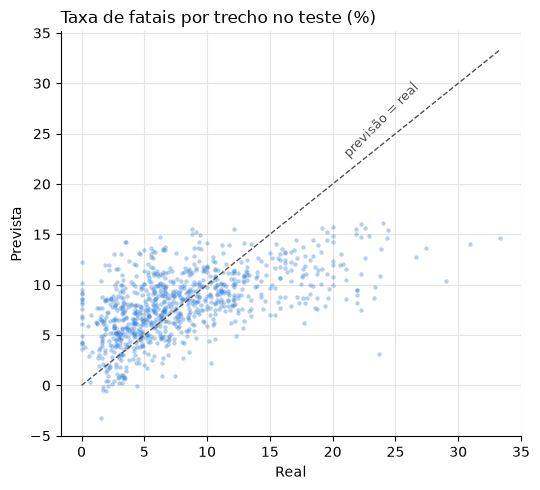

In [36]:
previsto = modelo.predict(X_teste)
limite = max(y_teste.max(), previsto.max())

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_teste, previsto, s=10, alpha=0.35, color="#2a78d6", linewidths=0)
ax.plot([0, limite], [0, limite], color="#52514e", linewidth=1, linestyle="--")
ax.annotate("previsão = real", (limite * 0.62, limite * 0.68), color="#52514e", fontsize=9, rotation=45)
ax.set_title("Taxa de fatais por trecho no teste (%)", loc="left")
ax.set_xlabel("Real")
ax.set_ylabel("Prevista")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e5e4e0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Leitura das métricas.**

- O R² do treino e o R² do teste são parecidos. O modelo não tem *overfitting*.
- O MAE do modelo é menor que o MAE da base. O modelo é melhor que a média.
- O R² é baixo (cerca de 0,3). A maior parte da variação da taxa de fatais vem de fatores que a base da PRF não tem, por exemplo o fluxo de veículos e a velocidade da via.
- O gráfico mostra que o modelo prevê valores perto da média: ele subestima os trechos com taxa muito alta.
- Alguns trechos têm uma previsão negativa. A regressão linear não limita a previsão entre 0% e 100%.

### 4.6 Coeficientes (β)

Cada β é a mudança da taxa de fatais (em pontos percentuais) quando uma variável aumenta 1 unidade e as outras ficam iguais.
As variáveis `pct_` estão em pontos percentuais. Assim, o β de `pct_pista_simples` é o efeito de 1 pp a mais de acidentes em pista simples.

In [37]:
regressao = modelo.named_steps["regressao"]

coeficientes = pd.DataFrame({"β": regressao.coef_}, index=X.columns)
coeficientes["efeito de 0% → 100%"] = (coeficientes["β"] * 100).where(coeficientes.index.str.startswith("pct_"))

print(f"Intercepto: {regressao.intercept_:.2f}")
coeficientes.sort_values("β", ascending=False).round(3)

Intercepto: 2.99


,β,efeito de 0% → 100%
regiao_Nordeste,2.502,NaN
regiao_Norte,1.684,NaN
pct_pedestre,0.422,42.210
pct_noite,0.110,10.962
pct_pista_simples,0.040,3.950
pct_velocidade,0.034,3.376
pct_curva,-0.007,-0.690
acidentes_por_ano,-0.014,NaN
pct_chuva,-0.029,-2.873
pct_urbano,-0.064,-6.364


A coluna "efeito de 0% → 100%" compara um trecho onde nenhum acidente tem a característica com um trecho onde todos têm.
Para as regiões, o β já é a diferença em relação ao Centro-Oeste. Para `acidentes_por_ano`, o β é o efeito de 1 acidente a mais por ano.

**Comparação: o β da pista simples sem controles e com controles.**

In [38]:
sozinha = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("regressao", LinearRegression()),
]).fit(X_treino[["pct_pista_simples"]], y_treino)

beta_sozinha = sozinha.named_steps["regressao"].coef_[0]
beta_controles = coeficientes.loc["pct_pista_simples", "β"]

print(f"β da pista simples, sem controles: {beta_sozinha:.4f} (0% → 100%: {beta_sozinha * 100:.1f} pp)")
print(f"β da pista simples, com controles: {beta_controles:.4f} (0% → 100%: {beta_controles * 100:.1f} pp)")
print(f"R² de teste só com a pista simples: {r2_score(y_teste, sozinha.predict(X_teste[['pct_pista_simples']])):.3f}")

β da pista simples, sem controles: 0.0476 (0% → 100%: 4.8 pp)
β da pista simples, com controles: 0.0395 (0% → 100%: 4.0 pp)
R² de teste só com a pista simples: 0.113


**Interpretação dos coeficientes.**

- **Pista simples.** Com os outros fatores iguais, um trecho só com pista simples tem cerca de 4 pp a mais de taxa de fatais que um trecho só com pista dupla ou múltipla.
  A taxa média é de 8%, então a diferença é grande. Com os controles, o efeito diminui de 4,8 pp para 4,0 pp. Os outros fatores explicam só uma parte pequena do efeito da pista simples.
- **Pedestre.** É o maior efeito por ponto percentual. Os atropelamentos têm uma taxa de fatais de cerca de 30% (seção 3.4).
- **Região.** Os trechos do Nordeste e do Norte têm uma taxa mais alta que os do Centro-Oeste. Os do Sul e do Sudeste têm uma taxa mais baixa.
- **Noite.** Mais acidentes à noite aumentam a taxa de fatais.
- **Urbano e volume.** Os trechos urbanos e os trechos com muitos acidentes por ano têm uma taxa mais baixa.
  Uma explicação possível: nesses trechos, a velocidade é menor e há mais acidentes leves.
- **Álcool.** O β é negativo. Este resultado não diz que o álcool protege. Os acidentes com álcool podem acontecer mais em trechos urbanos e com velocidade baixa.
  Um coeficiente mostra uma associação com as outras variáveis fixas, não uma causa.

**Limitações.**

- A regressão mostra uma associação, não uma causa. A duplicação de uma rodovia não é aleatória: as rodovias duplicadas também podem ter melhor sinalização e iluminação.
- O valor do β depende do método. A seção 4.7 mostra essa sensibilidade.
- A taxa de fatais é calculada por acidente, não por veículo. A PRF não registra o fluxo de veículos.

### 4.7 Análise de sensibilidade

**Problema.** O modelo da seção 4.5 tem duas escolhas de método:

- O mínimo de 30 acidentes por trecho.
- O mesmo peso para todos os trechos. Um trecho com 30 acidentes pesa o mesmo que um trecho com 3.000.

**Teste.** Treine o mesmo modelo com outros mínimos e com um peso igual ao número de acidentes do trecho.
Se o β da pista simples tem o mesmo sinal em todas as combinações, a conclusão não depende dessas escolhas.

Com o peso, o R² ponderado também usa o peso. Ele mede o erro por acidente, não por trecho.

In [39]:
sensibilidade = []

for minimo in [10, 30, 50, 100]:
    selecao = trechos[trechos["acidentes"] >= minimo].reset_index(drop=True)
    X_sens = pd.get_dummies(selecao[COLUNAS_PCT + ["acidentes_por_ano", "regiao"]], columns=["regiao"], drop_first=True, dtype=float)

    X_tr, X_te, y_tr, y_te, peso_tr, peso_te = train_test_split(
        X_sens, selecao["letalidade_trecho"], selecao["acidentes"], test_size=0.2, random_state=2903
    )

    for nome_peso, peso in [("igual", None), ("nº de acidentes", peso_tr)]:
        modelo_sens = Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("regressao", LinearRegression()),
        ]).fit(X_tr, y_tr, regressao__sample_weight=peso)

        previsto_sens = modelo_sens.predict(X_te)
        beta = modelo_sens.named_steps["regressao"].coef_[X_sens.columns.get_loc("pct_pista_simples")]

        sensibilidade.append({
            "mínimo": minimo,
            "peso": nome_peso,
            "trechos": len(selecao),
            "MAE teste": mean_absolute_error(y_te, previsto_sens),
            "R² teste": r2_score(y_te, previsto_sens),
            "R² ponderado teste": r2_score(y_te, previsto_sens, sample_weight=peso_te),
            "pista simples 0% → 100% (pp)": beta * 100,
        })

pd.DataFrame(sensibilidade).set_index(["mínimo", "peso"]).round(3)

trechos  MAE teste  R² teste  R² ponderado teste  pista simples 0% → 100% (pp)
mínimo peso                                                                                           
10     igual               8228      5.705     0.268               0.133                         5.187
       nº de acidentes     8228      5.661     0.218               0.412                         3.519
30     igual               4416      3.466     0.314               0.370                         3.950
       nº de acidentes     4416      3.379     0.300               0.441                         2.772
50     igual               2877      2.727     0.273               0.358                         2.891
       nº de acidentes     2877      2.732     0.234               0.374                         2.095
100    igual               1434      1.920     0.266               0.315                         1.217
       nº de acidentes     1434      1.875     0.270               0.345                         0.777

**Resultado.**

- O β da pista simples é positivo em todas as combinações. A associação entre pista simples e letalidade não depende do mínimo nem do peso.
- O valor do efeito muda muito: de cerca de 0,8 pp a 5,2 pp. O efeito diminui com o peso e quando o mínimo de acidentes aumenta.
  Nos dois casos, os trechos com muitos acidentes pesam mais. Esses trechos são, na maioria, corredores urbanos.
  A seção 5.6 mostra que, nos corredores urbanos, a pista simples e a pista dupla têm quase a mesma letalidade.
- Por isso, o notebook apresenta o efeito da pista simples como um intervalo, não como um único número.

## 5. Clustering K-Means

**Problema.** A regressão compara trechos muito diferentes. Um corredor urbano e uma serra rural não têm o mesmo risco, com ou sem duplicação.

**Solução.** Agrupe os trechos por perfil de acidentes. Depois, compare a pista simples e a pista dupla **dentro de cada grupo**.
Nesta comparação, os trechos de cada lado têm um perfil parecido. É o nível 2 da hipótese ("comparação justa").

O K-Means é aprendizado não supervisionado: ele não recebe a letalidade, só as características dos trechos.

In [40]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

### 5.1 Seleção das variáveis

O K-Means usa as variáveis numéricas contínuas da ficha do grupo. Todas são características do trecho:

| Variável | Significado |
|---|---|
| `acidentes_por_ano` | Volume de acidentes do trecho |
| `pct_noite` | % dos acidentes na fase "Plena Noite" |
| `pct_chuva` | % dos acidentes com chuva ou garoa |
| `pct_curva` | % dos acidentes com curva no traçado |
| `pct_fim_de_semana` | % dos acidentes no sábado ou no domingo |
| `media_veiculos` | Média de veículos por acidente |
| `media_pessoas` | Média de pessoas por acidente |

Duas variáveis ficam fora do K-Means:

- `pct_pista_simples`: a comparação da seção 5.6 separa a pista simples da pista dupla dentro de cada grupo. Se a pista entrar no K-Means, os grupos separam as pistas, e a comparação fica impossível.
- `letalidade_trecho`: é o resultado que a comparação mede.

O K-Means usa os mesmos 4.416 trechos da regressão (pelo menos 30 acidentes).

In [41]:
COLUNAS_CLUSTER = ["acidentes_por_ano", "pct_noite", "pct_chuva", "pct_curva",
                   "pct_fim_de_semana", "media_veiculos", "media_pessoas"]

trechos_cluster = trechos_reg.copy()
X_cluster = trechos_cluster[COLUNAS_CLUSTER].astype(float)

print("NaN:", int(X_cluster.isna().sum().sum()))
X_cluster.describe().round(2).T

NaN: 0


,count,mean,std,min,25%,50%,75%,max
acidentes_por_ano,4416.0,13.71,19.30,3.33,4.67,7.33,13.89,334.00
pct_noite,4416.0,35.39,8.95,7.32,29.17,35.22,41.12,71.79
pct_chuva,4416.0,15.93,10.49,0.00,8.77,13.65,20.21,83.78
pct_curva,4416.0,23.41,22.07,0.00,5.94,15.93,35.69,96.67
pct_fim_de_semana,4416.0,34.68,7.50,10.00,29.51,34.34,39.39,75.00
media_veiculos,4416.0,1.97,0.32,1.03,1.78,1.95,2.11,4.93
media_pessoas,4416.0,2.60,0.44,1.53,2.32,2.52,2.79,5.91


### 5.2 Assimetria e logaritmo

**Problema.** A distância euclidiana do K-Means é sensível a valores extremos. A variável `acidentes_por_ano` tem mediana 7 e máximo 334.
Sem tratamento, poucos trechos muito movimentados dominam a distância.

**Ação.** Aplique o logaritmo às três variáveis de contagem (`acidentes_por_ano`, `media_veiculos`, `media_pessoas`).
O logaritmo reduz a distância entre os valores grandes e mantém a ordem dos trechos.
As variáveis `pct_` ficam sem logaritmo, porque são limitadas entre 0 e 100.

In [42]:
COLUNAS_LOG = ["acidentes_por_ano", "media_veiculos", "media_pessoas"]

X_log = X_cluster.copy()
X_log[COLUNAS_LOG] = np.log(X_log[COLUNAS_LOG])

pd.DataFrame({
    "assimetria antes": X_cluster.skew(),
    "assimetria depois": X_log.skew(),
}).round(2)

,assimetria antes,assimetria depois
acidentes_por_ano,5.29,1.07
pct_noite,0.18,0.18
pct_chuva,1.66,1.66
pct_curva,1.09,1.09
pct_fim_de_semana,0.29,0.29
media_veiculos,1.27,0.36
media_pessoas,1.66,0.85


### 5.3 Padronização (`StandardScaler`)

**Problema.** As variáveis têm escalas diferentes. As variáveis `pct_` variam de 0 a 100, e o log de `media_veiculos` varia de 0 a 1,6.
Sem padronização, as variáveis `pct_` dominam a distância.

**Ação.** Aplique o Z-Score: cada coluna fica com média 0 e desvio-padrão 1.

In [43]:
escalador = StandardScaler()
Z = escalador.fit_transform(X_log)

pd.DataFrame(Z, columns=COLUNAS_CLUSTER).describe().loc[["mean", "std"]].round(3)

,acidentes_por_ano,pct_noite,pct_chuva,pct_curva,pct_fim_de_semana,media_veiculos,media_pessoas
mean,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 5.4 Escolha de K: cotovelo e silhueta

Treine o K-Means com K de 2 a 10. Para cada K, calcule:

- a **inércia** (WCSS): a soma das distâncias ao quadrado entre cada trecho e o centro do seu grupo. A inércia sempre diminui quando K aumenta.
- a **silhueta**: de −1 a +1. Um valor alto significa grupos compactos e separados.

In [44]:
diagnostico = []

for k in range(2, 11):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z)
    diagnostico.append({
        "K": k,
        "inércia": modelo_k.inertia_,
        "silhueta": silhouette_score(Z, modelo_k.labels_),
    })

diagnostico = pd.DataFrame(diagnostico).set_index("K")
diagnostico["queda da inércia"] = -diagnostico["inércia"].diff()
diagnostico.round(3)

,inércia,silhueta,queda da inércia
K,,,
2,25376.593,0.209,NaN
3,21542.879,0.178,3833.714
4,18730.854,0.176,2812.025
5,17293.399,0.169,1437.455
6,16327.267,0.167,966.132
7,15460.457,0.155,866.810
8,14838.439,0.145,622.018
9,14287.916,0.139,550.524
10,13800.642,0.138,487.273


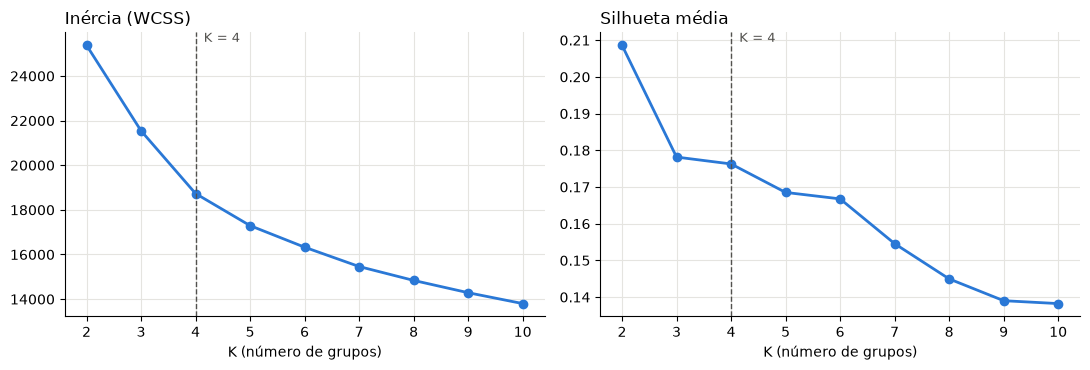

In [45]:
fig, (ax_inercia, ax_silhueta) = plt.subplots(1, 2, figsize=(11, 3.8))

ax_inercia.plot(diagnostico.index, diagnostico["inércia"], marker="o", color="#2a78d6", linewidth=2)
ax_inercia.set_title("Inércia (WCSS)", loc="left")

ax_silhueta.plot(diagnostico.index, diagnostico["silhueta"], marker="o", color="#2a78d6", linewidth=2)
ax_silhueta.set_title("Silhueta média", loc="left")

for ax in (ax_inercia, ax_silhueta):
    ax.axvline(4, color="#52514e", linestyle="--", linewidth=1)
    ax.annotate("K = 4", (4.15, ax.get_ylim()[1]), va="top", fontsize=9, color="#52514e")
    ax.set_xlabel("K (número de grupos)")
    ax.set_xticks(diagnostico.index)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e5e4e0")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Decisão: K = 4.**

- A curva da inércia não tem um cotovelo nítido. A queda de 3 para 4 é cerca de duas vezes a queda de 4 para 5. Depois de K = 4, cada grupo novo acrescenta pouco.
- A silhueta de K = 4 é quase igual à de K = 3. A silhueta de K = 2 é a maior, mas dois grupos são grosseiros demais para apoiar uma decisão.
- **Limitação.** A silhueta é baixa em todos os K (cerca de 0,2). Os perfis dos trechos variam de forma contínua, sem fronteiras nítidas.
  Os grupos são uma forma útil de resumir os perfis, não "tipos naturais" de trecho.

### 5.5 Treinamento final e personas

In [46]:
K = 4

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z)
trechos_cluster["cluster"] = kmeans.labels_

perfil = trechos_cluster.groupby("cluster").agg(
    trechos=("acidentes", "size"),
    **{coluna: (coluna, "mean") for coluna in COLUNAS_CLUSTER},
    pct_urbano=("pct_urbano", "mean"),
)
perfil.round(2)

,trechos,acidentes_por_ano,pct_noite,pct_chuva,pct_curva,pct_fim_de_semana,media_veiculos,media_pessoas,pct_urbano
cluster,,,,,,,,,
0,1020,33.83,34.80,11.996397,11.27,30.80,1.94,2.41,58.92
1,953,10.06,28.86,27.845365,53.41,33.71,1.77,2.43,8.53
2,1024,6.06,32.28,14.490117,17.89,32.32,2.31,3.1,16.79
3,1419,7.21,42.46,11.788839,15.98,39.81,1.87,2.5,27.39


A tabela usa a escala original (sem log e sem Z-Score). A coluna `pct_urbano` não entra no K-Means, mas ajuda a interpretar os grupos.

Cada grupo tem uma característica que o separa dos outros. A célula abaixo dá o nome a cada grupo por essa característica.
Ela não depende do número do cluster, porque o K-Means pode trocar os números numa execução nova.

In [47]:
REGRAS_PERSONA = {
    "Corredores urbanos movimentados": "acidentes_por_ano",
    "Serra com curva e chuva": "pct_curva",
    "Rurais com acidentes de vários veículos": "media_pessoas",
    "Noite e fim de semana": "pct_noite",
}

centros = pd.DataFrame(kmeans.cluster_centers_, columns=COLUNAS_CLUSTER)

persona_do_cluster = {}
for persona, coluna in REGRAS_PERSONA.items():
    persona_do_cluster[int(centros[coluna].idxmax())] = persona

assert len(persona_do_cluster) == K, "Duas regras escolheram o mesmo cluster."

trechos_cluster["persona"] = trechos_cluster["cluster"].map(persona_do_cluster)
perfil["persona"] = perfil.index.map(persona_do_cluster)

In [48]:
ACOES = {
    "Corredores urbanos movimentados": "Fiscalização de velocidade e travessias de pedestres. A duplicação tem pouco efeito (seção 5.6).",
    "Serra com curva e chuva": "Prioridade de duplicação. Também: drenagem, sinalização de curva e defensas.",
    "Rurais com acidentes de vários veículos": "Prioridade de duplicação. Também: faixas adicionais de ultrapassagem.",
    "Noite e fim de semana": "Prioridade de duplicação. Também: iluminação e fiscalização noturna de álcool.",
}

tabela_executiva = trechos_cluster.groupby("persona").agg(
    trechos=("acidentes", "size"),
    acidentes_por_ano=("acidentes_por_ano", "mean"),
    pct_noite=("pct_noite", "mean"),
    pct_chuva=("pct_chuva", "mean"),
    pct_curva=("pct_curva", "mean"),
    pct_fim_de_semana=("pct_fim_de_semana", "mean"),
    media_veiculos=("media_veiculos", "mean"),
    media_pessoas=("media_pessoas", "mean"),
    pct_urbano=("pct_urbano", "mean"),
    pct_pista_simples=("pct_pista_simples", "mean"),
    letalidade_media=("letalidade_trecho", "mean"),
).round(2)
tabela_executiva["ação sugerida"] = tabela_executiva.index.map(ACOES)

tabela_executiva.sort_values("letalidade_media", ascending=False)

,trechos,acidentes_por_ano,pct_noite,pct_chuva,pct_curva,pct_fim_de_semana,media_veiculos,media_pessoas,pct_urbano,pct_pista_simples,letalidade_media,ação sugerida
persona,,,,,,,,,,,,
Rurais com acidentes de vários veículos,1024,6.06,32.28,14.490117,17.89,32.32,2.31,3.1,16.79,85.59,10.08,Prioridade de duplicação. Também: faixas adici...
Noite e fim de semana,1419,7.21,42.46,11.788839,15.98,39.81,1.87,2.5,27.39,70.83,9.56,Prioridade de duplicação. Também: iluminação e...
Serra com curva e chuva,953,10.06,28.86,27.845365,53.41,33.71,1.77,2.43,8.53,60.13,7.18,"Prioridade de duplicação. Também: drenagem, si..."
Corredores urbanos movimentados,1020,33.83,34.80,11.996397,11.27,30.80,1.94,2.41,58.92,37.56,4.64,Fiscalização de velocidade e travessias de ped...


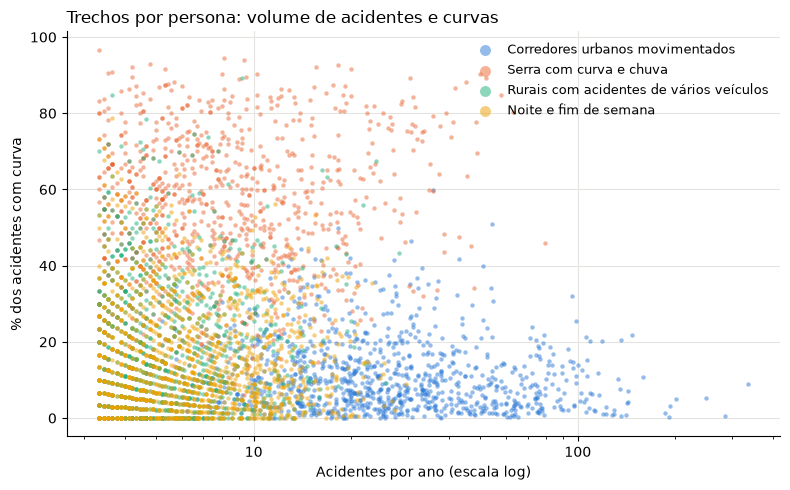

In [49]:
CORES_PERSONA = {
    "Corredores urbanos movimentados": "#2a78d6",
    "Serra com curva e chuva": "#eb6834",
    "Rurais com acidentes de vários veículos": "#1baf7a",
    "Noite e fim de semana": "#eda100",
}

fig, ax = plt.subplots(figsize=(8, 5))

for persona, cor in CORES_PERSONA.items():
    grupo = trechos_cluster[trechos_cluster["persona"] == persona]
    ax.scatter(grupo["acidentes_por_ano"], grupo["pct_curva"], s=10, alpha=0.5, color=cor, linewidths=0, label=persona)

ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_title("Trechos por persona: volume de acidentes e curvas", loc="left")
ax.set_xlabel("Acidentes por ano (escala log)")
ax.set_ylabel("% dos acidentes com curva")
ax.legend(loc="upper right", frameon=False, markerscale=2.5, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e5e4e0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

O gráfico mostra só duas das sete variáveis. Os corredores urbanos (muitos acidentes) e a serra (muitas curvas) ficam separados.
Os outros dois grupos se separam por variáveis que o gráfico não mostra (noite, fim de semana, pessoas por acidente).

### 5.6 Nível 2 da hipótese: pista simples × pista dupla dentro de cada persona

**Método.**

- Classifique cada trecho pela pista predominante: "simples" se pelo menos 80% dos acidentes são em pista simples, "dupla ou múltipla" se no máximo 20%. Os outros trechos ficam como "misto" e saem da comparação.
- Em cada persona, calcule a letalidade do conjunto: o total de acidentes fatais dividido pelo total de acidentes. Assim, cada acidente tem o mesmo peso.

In [50]:
trechos_cluster["pista_predominante"] = np.select(
    [trechos_cluster["pct_pista_simples"] >= 80, trechos_cluster["pct_pista_simples"] <= 20],
    ["simples", "dupla ou múltipla"],
    "misto",
)
trechos_cluster["fatais"] = trechos_cluster["letalidade_trecho"] / 100 * trechos_cluster["acidentes"]

comparacao = (
    trechos_cluster[trechos_cluster["pista_predominante"] != "misto"]
    .groupby(["persona", "pista_predominante"])
    .agg(trechos=("acidentes", "size"), acidentes=("acidentes", "sum"), fatais=("fatais", "sum"))
)
comparacao["letalidade (%)"] = comparacao["fatais"] / comparacao["acidentes"] * 100

letalidade = comparacao["letalidade (%)"].unstack("pista_predominante")
letalidade["diferença (pp)"] = letalidade["simples"] - letalidade["dupla ou múltipla"]
letalidade["trechos simples"] = comparacao["trechos"].unstack("pista_predominante")["simples"]
letalidade["trechos dupla ou múltipla"] = comparacao["trechos"].unstack("pista_predominante")["dupla ou múltipla"]

letalidade.sort_values("diferença (pp)", ascending=False).round(2)

pista_predominante,dupla ou múltipla,simples,diferença (pp),trechos simples,trechos dupla ou múltipla
persona,,,,,
Serra com curva e chuva,4.65,8.13,3.48,523,322
Rurais com acidentes de vários veículos,6.72,10.08,3.35,848,80
Noite e fim de semana,6.80,9.95,3.15,924,309
Corredores urbanos movimentados,3.80,3.90,0.10,258,550


**Resultado.**

- Em três personas (serra, rurais com vários veículos, noite e fim de semana), a pista simples tem uma letalidade cerca de 3 a 3,5 pp mais alta que a pista dupla.
  Os trechos dos dois lados têm um perfil parecido, então a diferença não vem do perfil do trecho.
- Nos **corredores urbanos movimentados**, a pista simples e a pista dupla têm quase a mesma letalidade.
  Nesses trechos, a velocidade é provavelmente baixa, e a duplicação tem pouco efeito sobre a letalidade.
- **Consequência para a decisão:** a duplicação deve ter prioridade nos trechos de pista simples fora dos corredores urbanos.

**Limitações.**

- A comparação ainda é uma associação. Dentro de uma persona, os trechos duplicados podem ter outras diferenças (sinalização, iluminação, idade da obra).
- Na persona "Rurais com acidentes de vários veículos", há poucos trechos de pista dupla. A letalidade desse lado tem mais incerteza.
- O nível 3 da hipótese (o mesmo trecho antes e depois da duplicação) é o teste mais forte. Ele fica para a próxima etapa.